In [1]:
from google.colab import files
uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/social_media_engagement_5000.csv")
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [3]:
print("Rows, columns:", df.shape)
df.info()
df.describe()

Rows, columns: (5000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment       

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348


In [4]:
df.isnull().sum()
print("Full duplicate rows:", df.duplicated().sum())
print("Repeated post_ids:", df['post_id'].duplicated().sum())

Full duplicate rows: 0
Repeated post_ids: 9


In [11]:
df['posted_at'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y')
df['posted_at'].dtype

dtype('<M8[ns]')

In [14]:
dups = df[df['post_id'].duplicated(keep=False)].sort_values('post_id')
dups


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


In [15]:
df = df.drop_duplicates(subset='post_id', keep='first')
df.shape

(4991, 19)

In [16]:
df['age'] = df['age'].fillna(df['age'].median())

for col in ['likes', 'comments', 'shares']:
    df[col] = df[col].fillna(df[col].median())

df['gender'] = df['gender'].fillna('Unknown')
df['sentiment'] = df['sentiment'].fillna('Unknown')

df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


Upper limit: 1.0392355647025773
Outliers: 578


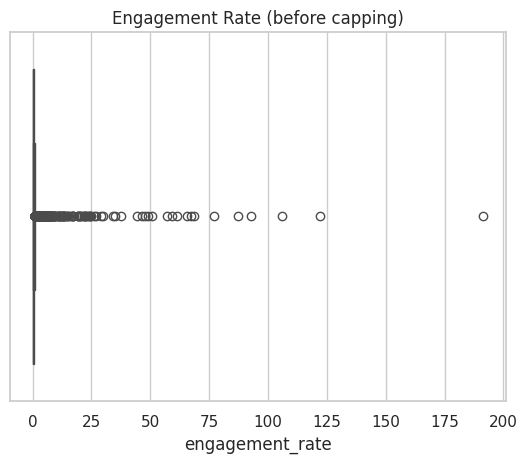

In [28]:
df['total_engagement'] = df['likes'] + df['comments'] + df['shares']
df['engagement_rate'] = df['total_engagement'] / df['impression_count']

Q1 = df['engagement_rate'].quantile(0.25)
Q3 = df['engagement_rate'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

print("Upper limit:", upper)
print("Outliers:", (df['engagement_rate'] > upper).sum())

sns.boxplot(x=df['engagement_rate'])
plt.title("Engagement Rate (before capping)")
plt.show()

In [29]:
# Option A: cap extreme values
df['engagement_rate_capped'] = df['engagement_rate'].clip(upper=upper)

# Option B: keep them but use the median instead of the mean in your analysis

In [30]:
df['year'] = df['posted_at'].dt.year
df['month'] = df['posted_at'].dt.month
df['day_of_week'] = df['posted_at'].dt.day_name()
df['hashtag_count'] = df['hashtags'].str.split().str.len()
df['age_group'] = pd.cut(df['age'], bins=[0, 24, 34, 44, 54, 100],
                         labels=['<25', '25-34', '35-44', '45-54', '55+'])
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,sentiment,hashtags,engagement_rate,total_engagement,engagement_rate_capped,year,month,day_of_week,hashtag_count,age_group
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,negative,#foodie #travel #love,0.190862,8522.0,0.190862,2022,12,Saturday,3,35-44
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,negative,#fitness,0.201493,16163.0,0.201493,2023,6,Friday,1,25-34
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,...,positive,#foodie,0.137345,6161.0,0.137345,2023,5,Sunday,1,25-34
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,negative,#music #foodie #fun,0.106195,7482.0,0.106195,2023,2,Sunday,3,45-54
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,negative,#travel,2.777372,16717.0,1.039236,2023,5,Tuesday,1,25-34


In [32]:
# Which post type gets the most engagement?
df.groupby('post_type')['engagement_rate_capped'].mean().sort_values(ascending=False)


,engagement_rate_capped
post_type,
text,0.381852
video,0.381475
image,0.377061
reel,0.364100


In [34]:
# Which content category?
df.groupby('post_category')['total_engagement'].mean().sort_values(ascending=False)



,total_engagement
post_category,
music,12801.914826
food,12720.310811
tech,12686.433083
travel,12651.787145
lifestyle,12647.279801
education,12571.527778
fitness,12450.304896
fashion,12352.824621


In [35]:
# Which country and device?
df.groupby('country')['engagement_rate_capped'].mean().sort_values(ascending=False)
df.groupby('device_type')['engagement_rate_capped'].mean()


,engagement_rate_capped
device_type,
desktop,0.374066
mobile,0.380199
tablet,0.373696


In [36]:
# Verified vs. not verified
df.groupby('is_verified')['engagement_rate_capped'].mean()


,engagement_rate_capped
is_verified,
False,0.378162
True,0.355777


In [39]:
# Sentiment and age group
df.groupby('sentiment')['engagement_rate_capped'].mean()
df.groupby('age_group', observed=True)['engagement_rate_capped'].mean()



,engagement_rate_capped
age_group,
<25,0.385344
25-34,0.379909
35-44,0.377512
45-54,0.375980
55+,0.359226


In [40]:
# Best day of the week
df.groupby('day_of_week')['engagement_rate_capped'].mean().sort_values(ascending=False)

,engagement_rate_capped
day_of_week,
Thursday,0.392286
Wednesday,0.384828
Friday,0.381511
Saturday,0.372302
Sunday,0.372232
Monday,0.368032
Tuesday,0.361520


In [41]:
# Top hashtags (split because each post has several)
tags = df.assign(tag=df['hashtags'].str.split()).explode('tag')
tags.groupby('tag')['engagement_rate_capped'].agg(['mean', 'count']).sort_values('mean', ascending=False).head(10)

,mean,count
tag,,
#fitness,0.401849,977
#fashion,0.384138,1005
#foodie,0.377570,1033
#travel,0.375129,932
#music,0.372159,983
#tech,0.370696,1044
#lifestyle,0.370325,1022
#love,0.369022,971
#fun,0.368943,1005


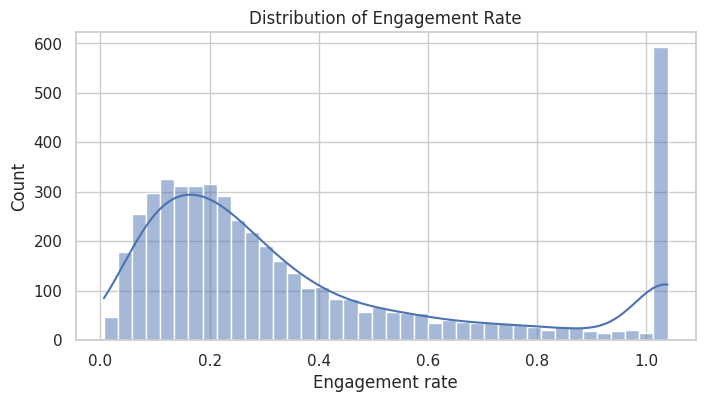

In [42]:
# 1. Distribution of engagement
plt.figure(figsize=(8, 4))
sns.histplot(df['engagement_rate_capped'], bins=40, kde=True)
plt.title("Distribution of Engagement Rate")
plt.xlabel("Engagement rate")
plt.show()

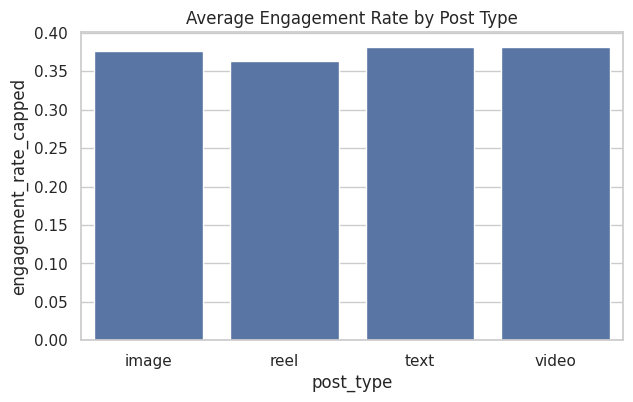

In [43]:
# 2. Engagement by post type
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x='post_type', y='engagement_rate_capped', estimator='mean', errorbar=None)
plt.title("Average Engagement Rate by Post Type")
plt.show()

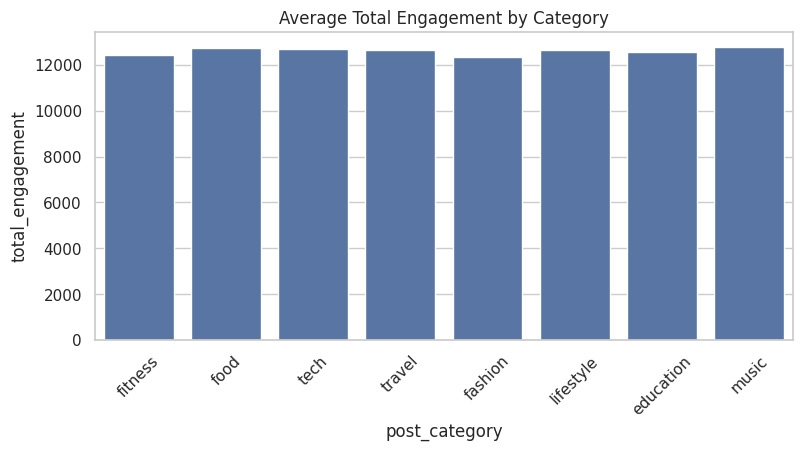

In [44]:
# 3. Engagement by category
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='post_category', y='total_engagement', errorbar=None)
plt.xticks(rotation=45)
plt.title("Average Total Engagement by Category")
plt.show()

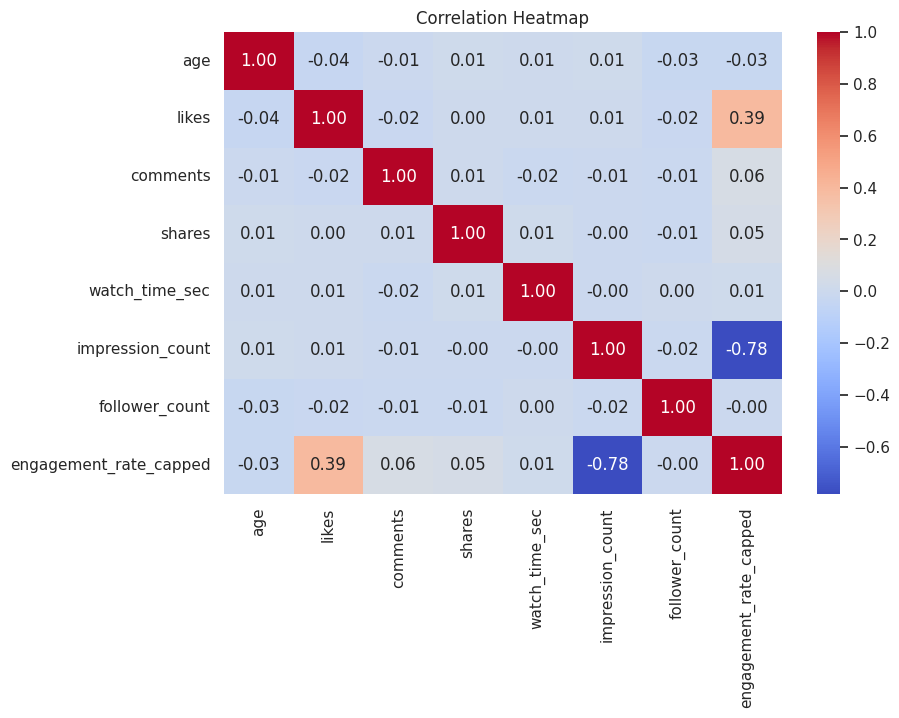

In [45]:
# 4. Correlation heatmap
num_cols = ['age', 'likes', 'comments', 'shares', 'watch_time_sec',
            'impression_count', 'follower_count', 'engagement_rate_capped']
plt.figure(figsize=(9, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

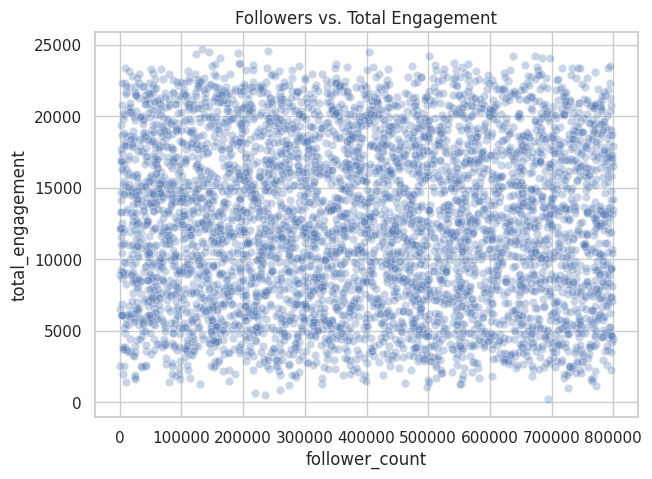

In [46]:
# 5. Followers vs. engagement
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='follower_count', y='total_engagement', alpha=0.3)
plt.title("Followers vs. Total Engagement")
plt.show()

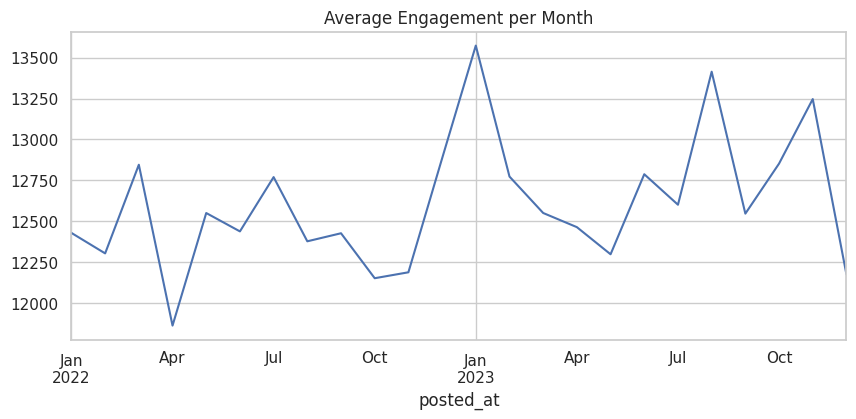

In [47]:
# 6. Trend over time
monthly = df.set_index('posted_at')['total_engagement'].resample('ME').mean()
monthly.plot(figsize=(10, 4), title="Average Engagement per Month")
plt.show()

R²: -0.07870642478905987
MAE: 5086.4176276276285


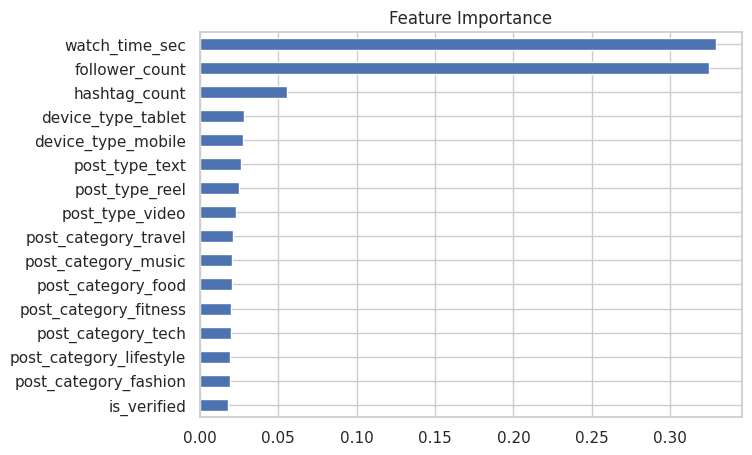

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

features = ['post_type', 'post_category', 'device_type', 'is_verified',
            'follower_count', 'hashtag_count', 'watch_time_sec']
X = pd.get_dummies(df[features], drop_first=True)
y = df['total_engagement']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("R²:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))

pd.Series(model.feature_importances_, index=X.columns).sort_values().plot(kind='barh', figsize=(7, 5))
plt.title("Feature Importance")
plt.show()